<a href="https://colab.research.google.com/github/mrupendrakushwaha/Seasonal-Agriculture-Performance-Analysis/blob/main/Seasonal_Agriculture_Performance_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Dataset Loading and Initial Exploration

In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [41]:
df = pd.read_csv("seasonal_agriculture_performance_dataset.csv")

df.head()

,Farm_ID,State,District,Crop,Season,Farm_Area_Hectares,Rainfall_mm,Avg_Temperature_C,Humidity_pct,Sunlight_Hours_Day,...,Seed_Quality_Score,Yield_Tonnes_Ha,Production_Tonnes,Market_Price_INR_Tonne,Total_Cost_INR,Revenue_INR,Profit_INR,Water_Used_m3,Water_Efficiency_t_per_1000m3,Disease_Pest_Risk_pct
0,SF10001,Andhra Pradesh,Rajkot,Wheat,Kharif,0.53,486.4,24.3,69.1,5.8,...,0.76,2.46,1.30,23700,42662,30810,-11852,237,5.485,55.3
1,SF10002,Maharashtra,Nalgonda,Maize,Kharif,6.53,855.4,25.7,78.4,5.1,...,0.94,0.30,1.96,20613,492351,40401,-451950,4953,0.396,49.9
2,SF10003,Telangana,Warangal,Pulses,Rabi,4.86,455.6,23.9,56.4,10.3,...,0.98,0.52,2.53,75283,315210,190466,-124744,1275,1.984,33.7
3,SF10004,Telangana,Indore,Rice,Kharif,4.50,753.2,29.7,65.2,6.3,...,0.74,1.84,8.28,24244,296444,200740,-95704,3834,2.160,50.6
4,SF10005,Karnataka,Ludhiana,Maize,Zaid,4.21,101.6,34.1,55.2,6.5,...,0.90,2.21,9.30,20818,337959,193607,-144352,3287,2.829,32.3


## Dataset Size

In [42]:
df.shape

(4000, 28)

## Dataset Columns

In [43]:
df.columns

Index(['Farm_ID', 'State', 'District', 'Crop', 'Season', 'Farm_Area_Hectares',
       'Rainfall_mm', 'Avg_Temperature_C', 'Humidity_pct',
       'Sunlight_Hours_Day', 'Soil_pH', 'Soil_Moisture_pct', 'Nitrogen_kg_ha',
       'Phosphorus_kg_ha', 'Potassium_kg_ha', 'Irrigation_Method',
       'Fertilizer_kg_ha', 'Pesticide_Litre_ha', 'Seed_Quality_Score',
       'Yield_Tonnes_Ha', 'Production_Tonnes', 'Market_Price_INR_Tonne',
       'Total_Cost_INR', 'Revenue_INR', 'Profit_INR', 'Water_Used_m3',
       'Water_Efficiency_t_per_1000m3', 'Disease_Pest_Risk_pct'],
      dtype='object')

## Data Types and Dataset Structure

In [44]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 28 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Farm_ID                        4000 non-null   object 
 1   State                          4000 non-null   object 
 2   District                       4000 non-null   object 
 3   Crop                           4000 non-null   object 
 4   Season                         4000 non-null   object 
 5   Farm_Area_Hectares             4000 non-null   float64
 6   Rainfall_mm                    3952 non-null   float64
 7   Avg_Temperature_C              4000 non-null   float64
 8   Humidity_pct                   4000 non-null   float64
 9   Sunlight_Hours_Day             4000 non-null   float64
 10  Soil_pH                        4000 non-null   float64
 11  Soil_Moisture_pct              3960 non-null   float64
 12  Nitrogen_kg_ha                 4000 non-null   f

## Statistical Summary

In [45]:
df.describe()

,Farm_Area_Hectares,Rainfall_mm,Avg_Temperature_C,Humidity_pct,Sunlight_Hours_Day,Soil_pH,Soil_Moisture_pct,Nitrogen_kg_ha,Phosphorus_kg_ha,Potassium_kg_ha,...,Seed_Quality_Score,Yield_Tonnes_Ha,Production_Tonnes,Market_Price_INR_Tonne,Total_Cost_INR,Revenue_INR,Profit_INR,Water_Used_m3,Water_Efficiency_t_per_1000m3,Disease_Pest_Risk_pct
count,4000.000000,3952.000000,4000.00000,4000.000000,4000.000000,4000.000000,3960.000000,4000.000000,4000.000000,4000.000000,...,4000.000000,3968.000000,4000.000000,4000.000000,4.000000e+03,4.000000e+03,4.000000e+03,4000.000000,4000.000000,4000.000000
mean,7.888265,601.152657,26.81890,63.210500,7.323050,6.701010,26.508232,120.250825,57.781850,104.760050,...,0.826138,5.270595,43.246210,44714.166250,5.263036e+05,6.378600e+05,1.115565e+05,6045.570250,5.385214,46.365875
std,4.223764,288.925025,3.81818,11.960834,1.121186,0.641461,6.712484,31.216452,17.015074,27.742681,...,0.101747,13.361398,126.880521,30266.161922,2.944191e+05,6.369747e+05,5.450819e+05,5572.944306,8.838101,12.424417
min,0.500000,80.000000,16.20000,25.000000,3.500000,5.200000,8.000000,40.000000,15.000000,30.000000,...,0.650000,0.300000,0.150000,2594.000000,2.682600e+04,6.107000e+03,-1.019223e+06,128.000000,0.135000,5.000000
25%,4.260000,370.200000,23.90000,54.775000,6.600000,6.260000,21.700000,98.500000,46.200000,86.200000,...,0.740000,1.050000,5.020000,21429.250000,2.745775e+05,2.075172e+05,-1.487318e+05,2268.750000,1.661000,37.300000
50%,7.895000,582.000000,26.90000,63.000000,7.300000,6.690000,26.400000,120.100000,57.500000,105.100000,...,0.830000,1.740000,11.770000,25913.000000,5.190825e+05,4.568305e+05,3.673000e+03,4435.000000,2.937500,46.400000
75%,11.650000,834.950000,29.60000,71.900000,8.100000,7.140000,31.300000,141.225000,69.400000,123.600000,...,0.910000,2.840000,24.355000,68279.000000,7.619965e+05,8.368748e+05,2.161878e+05,7829.750000,5.150250,54.900000
max,15.000000,1395.200000,39.70000,95.000000,11.000000,8.400000,47.000000,220.000000,120.000000,200.000000,...,1.000000,101.440000,1424.400000,131240.000000,1.349990e+06,5.080900e+06,4.345421e+06,40902.000000,79.800000,88.900000


## Categorical Variables

In [46]:
df.select_dtypes(include='object').columns

Index(['Farm_ID', 'State', 'District', 'Crop', 'Season', 'Irrigation_Method'], dtype='object')

## Category Frequencies

In [47]:
print("Season:")
print(df['Season'].value_counts())

print("\nCrop:")
print(df['Crop'].value_counts())

print("\nIrrigation Method:")
print(df['Irrigation_Method'].value_counts())

Season:
Season
Kharif    1779
Rabi      1627
Zaid       594
Name: count, dtype: int64

Crop:
Crop
Rice         690
Wheat        614
Maize        551
Cotton       508
Pulses       496
Groundnut    424
Chilli       412
Sugarcane    305
Name: count, dtype: int64

Irrigation Method:
Irrigation_Method
Flood        1310
Rainfed      1041
Drip          915
Sprinkler     734
Name: count, dtype: int64


## Missing Values Analysis

In [48]:
df.isnull().sum()

,0
Farm_ID,0
State,0
District,0
Crop,0
Season,0
Farm_Area_Hectares,0
Rainfall_mm,48
Avg_Temperature_C,0
Humidity_pct,0
Sunlight_Hours_Day,0


## Duplicate Records

In [49]:
df.duplicated().sum()

np.int64(0)

## Data Cleaning

In [50]:
df = df.drop_duplicates()

In [51]:
numeric_columns = df.select_dtypes(include='number').columns

df[numeric_columns] = df[numeric_columns].fillna(
    df[numeric_columns].median()
)

In [52]:
categorical_columns = df.select_dtypes(include='object').columns

for column in categorical_columns:
    df[column] = df[column].fillna(df[column].mode()[0])

## Final Data Quality Check

In [53]:
df.isnull().sum()

,0
Farm_ID,0
State,0
District,0
Crop,0
Season,0
Farm_Area_Hectares,0
Rainfall_mm,0
Avg_Temperature_C,0
Humidity_pct,0
Sunlight_Hours_Day,0


## Seasonal Distribution

In [54]:
season_counts = df['Season'].value_counts()

season_counts

,count
Season,
Kharif,1779
Rabi,1627
Zaid,594


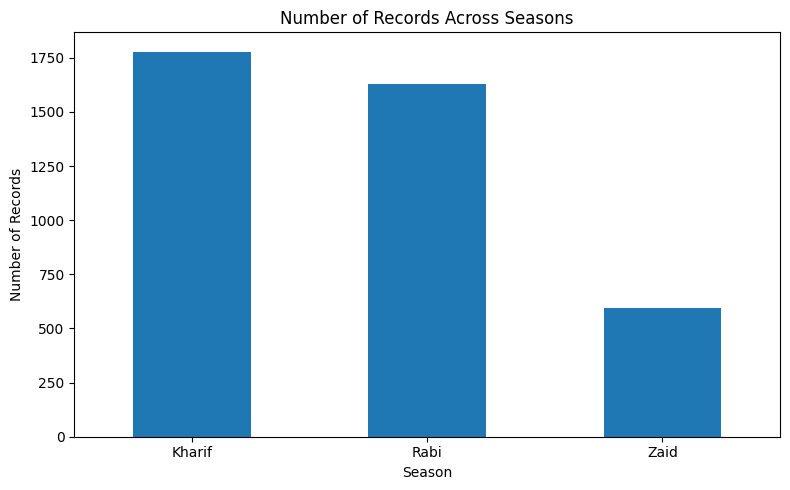

In [55]:
season_counts.plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title('Number of Records Across Seasons')
plt.xlabel('Season')
plt.ylabel('Number of Records')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Agricultural Performance Across Seasons

In [56]:
seasonal_performance = df.groupby('Season')[
    ['Yield_Tonnes_Ha', 'Production_Tonnes']
].mean()

seasonal_performance

,Yield_Tonnes_Ha,Production_Tonnes
Season,,
Kharif,5.628612,46.311192
Rabi,5.039435,41.486712
Zaid,4.641313,38.886111


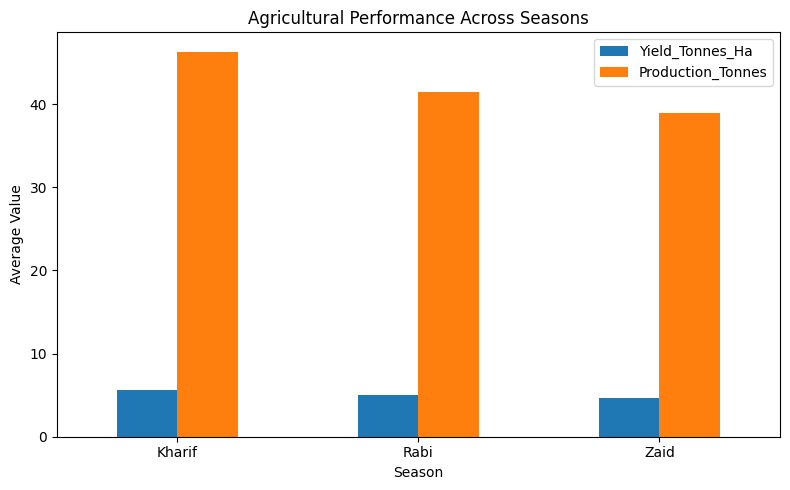

In [57]:
seasonal_performance.plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title('Agricultural Performance Across Seasons')
plt.xlabel('Season')
plt.ylabel('Average Value')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Environmental Conditions Across Seasons

In [58]:
environmental_summary = df.groupby('Season')[
    [
        'Rainfall_mm',
        'Avg_Temperature_C',
        'Humidity_pct',
        'Sunlight_Hours_Day',
        'Soil_pH',
        'Soil_Moisture_pct'
    ]
].mean()

environmental_summary

,Rainfall_mm,Avg_Temperature_C,Humidity_pct,Sunlight_Hours_Day,Soil_pH,Soil_Moisture_pct
Season,,,,,,
Kharif,849.199663,28.454019,71.812591,6.793367,6.727993,31.149859
Rabi,437.615366,23.489183,57.893178,7.589797,6.673749,24.069392
Zaid,304.654714,31.042088,52.012121,8.178788,6.694865,19.279630


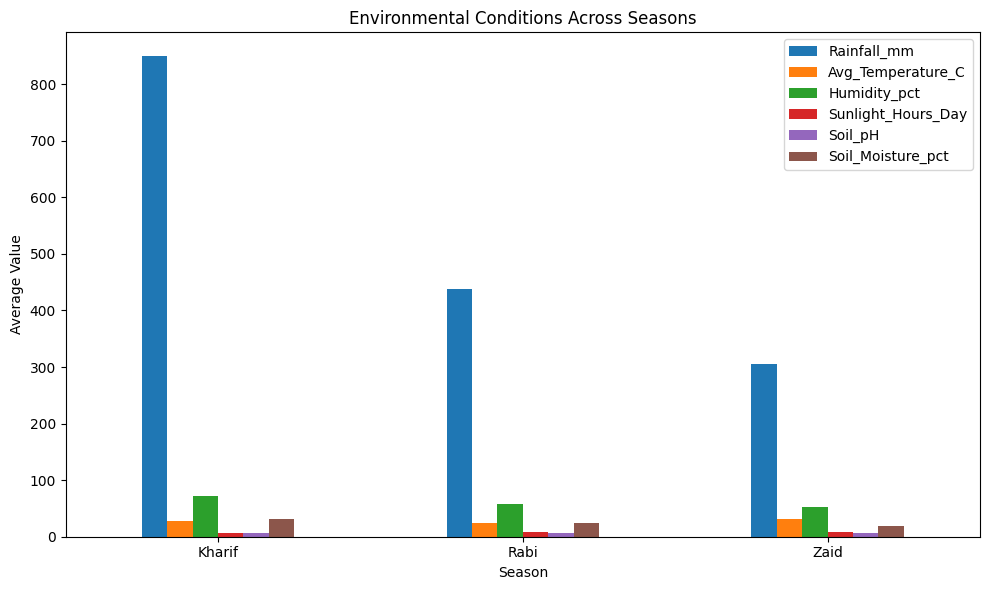

In [59]:
environmental_summary.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Environmental Conditions Across Seasons')
plt.xlabel('Season')
plt.ylabel('Average Value')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Relationship Between Environmental Conditions and Yield

In [60]:
environmental_columns = [
    'Rainfall_mm',
    'Avg_Temperature_C',
    'Humidity_pct',
    'Sunlight_Hours_Day',
    'Soil_pH',
    'Soil_Moisture_pct'
]

environmental_yield_corr = df[
    environmental_columns + ['Yield_Tonnes_Ha']
].corr()['Yield_Tonnes_Ha'].sort_values(
    ascending=False
)

environmental_yield_corr

,Yield_Tonnes_Ha
Yield_Tonnes_Ha,1.000000
Rainfall_mm,0.030951
Humidity_pct,0.012297
Soil_Moisture_pct,0.010999
Avg_Temperature_C,0.009996
Sunlight_Hours_Day,-0.015341
Soil_pH,-0.020672


## Resource Usage Across Seasons

In [61]:
resource_summary = df.groupby('Season')[
    [
        'Fertilizer_kg_ha',
        'Pesticide_Litre_ha',
        'Water_Used_m3',
        'Water_Efficiency_t_per_1000m3'
    ]
].mean()

resource_summary

,Fertilizer_kg_ha,Pesticide_Litre_ha,Water_Used_m3,Water_Efficiency_t_per_1000m3
Season,,,,
Kharif,187.077965,5.079747,6102.201237,5.891834
Rabi,185.407068,5.024690,5846.987093,5.186122
Zaid,184.638047,5.171212,6419.893939,4.413239


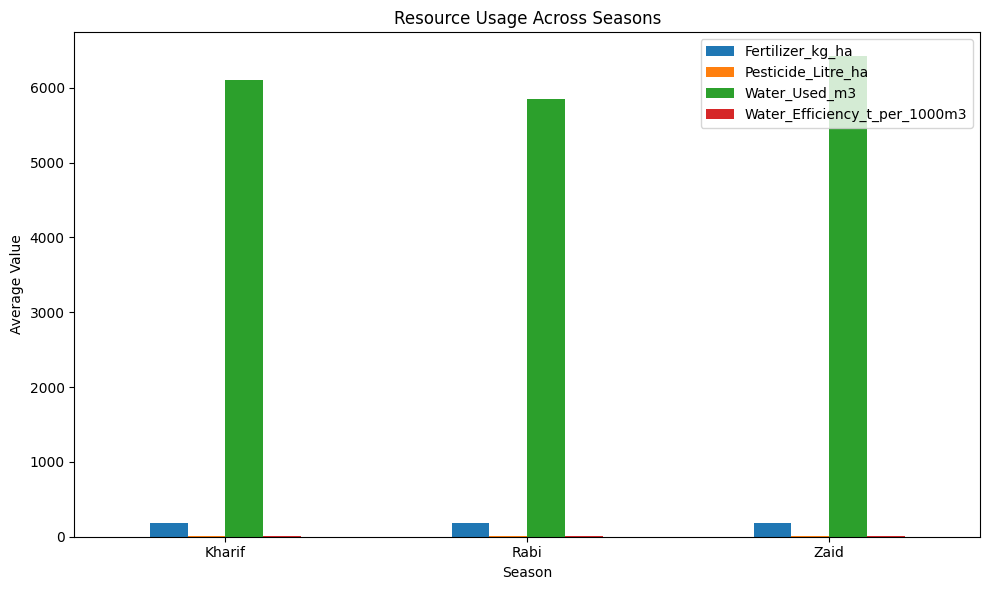

In [62]:
resource_summary.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Resource Usage Across Seasons')
plt.xlabel('Season')
plt.ylabel('Average Value')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Economic Outcomes Across Seasons

In [63]:
economic_summary = df.groupby('Season')[
    [
        'Market_Price_INR_Tonne',
        'Total_Cost_INR',
        'Revenue_INR',
        'Profit_INR'
    ]
].mean()

economic_summary

,Market_Price_INR_Tonne,Total_Cost_INR,Revenue_INR,Profit_INR
Season,,,,
Kharif,44850.906127,531804.408094,710719.055649,178914.647555
Rabi,44747.974800,513836.578365,601526.048556,87689.470191
Zaid,44212.033670,543976.728956,519171.904040,-24804.824916


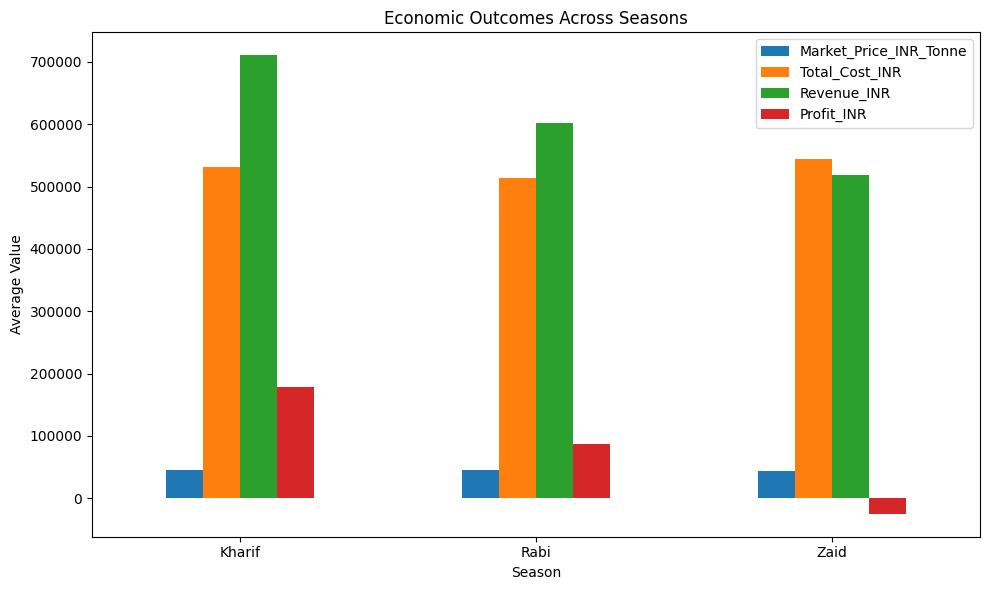

In [64]:
economic_summary.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Economic Outcomes Across Seasons')
plt.xlabel('Season')
plt.ylabel('Average Value')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Crop-wise Seasonal Comparison

In [65]:
crop_season_performance = df.groupby(
    ['Season', 'Crop']
)['Yield_Tonnes_Ha'].mean().unstack()

crop_season_performance

Crop,Chilli,Cotton,Groundnut,Maize,Pulses,Rice,Sugarcane,Wheat
Season,,,,,,,,
Kharif,1.731459,1.374512,1.484974,2.966410,1.036063,2.698376,53.459120,2.253664
Rabi,1.465031,1.198358,1.233164,2.603648,0.875962,2.322847,43.286124,2.057468
Zaid,1.195312,0.960217,1.037778,2.290952,0.669677,1.900490,38.423922,1.748588


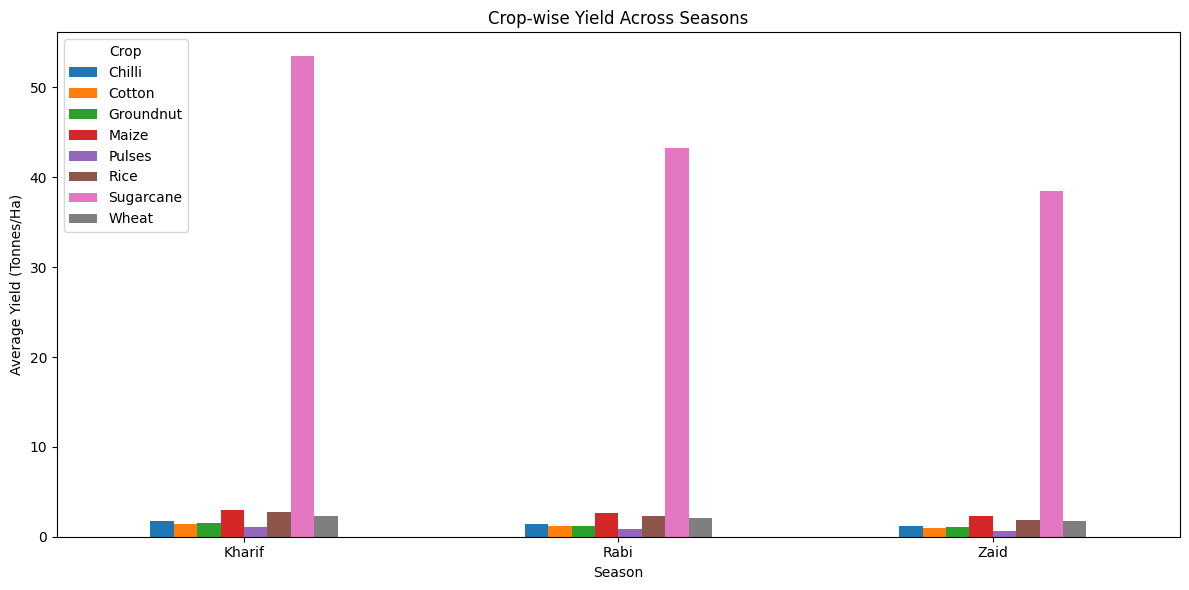

In [66]:
crop_season_performance.plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title('Crop-wise Yield Across Seasons')
plt.xlabel('Season')
plt.ylabel('Average Yield (Tonnes/Ha)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Statistical Analysis

In [67]:
from scipy.stats import f_oneway

kharif_yield = df[df['Season'] == 'Kharif']['Yield_Tonnes_Ha']
rabi_yield = df[df['Season'] == 'Rabi']['Yield_Tonnes_Ha']
zaid_yield = df[df['Season'] == 'Zaid']['Yield_Tonnes_Ha']

f_stat, p_value = f_oneway(
    kharif_yield,
    rabi_yield,
    zaid_yield
)

print("F-statistic:", f_stat)
print("p-value:", p_value)

F-statistic: 1.5438804542488311
p-value: 0.21367813841792296


In [68]:
if p_value < 0.05:
    print("There is a statistically significant difference in yield across seasons.")
else:
    print("There is no statistically significant difference in yield across seasons.")

There is no statistically significant difference in yield across seasons.


## Unusual Seasonal Patterns

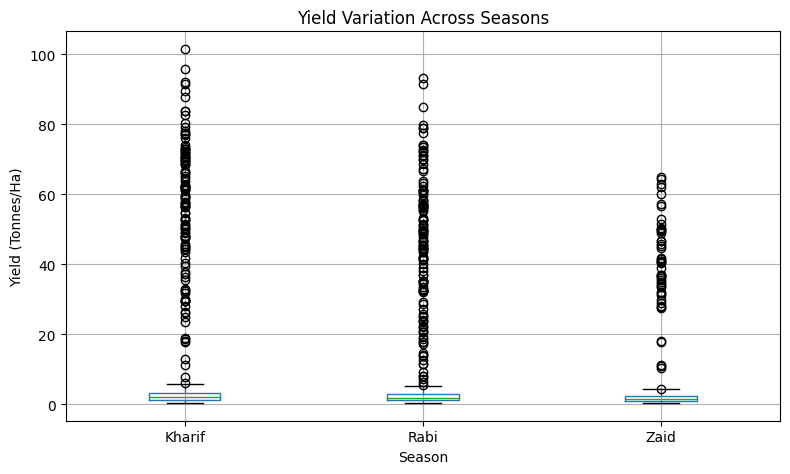

In [69]:
df.boxplot(
    column='Yield_Tonnes_Ha',
    by='Season',
    figsize=(8, 5)
)

plt.title('Yield Variation Across Seasons')
plt.suptitle('')
plt.xlabel('Season')
plt.ylabel('Yield (Tonnes/Ha)')
plt.tight_layout()
plt.show()

## Key Findings

- Kharif season had the highest average yield of 5.63 Tonnes/Ha, followed by Rabi at 5.04 Tonnes/Ha and Zaid at 4.64 Tonnes/Ha.
- Kharif also had the highest average production at 46.31 Tonnes, followed by Rabi at 41.49 Tonnes and Zaid at 38.89 Tonnes.
- Kharif recorded the highest average rainfall at 849.20 mm, while Zaid recorded the lowest at 304.65 mm.
- Zaid had the highest average temperature at 31.04°C and the highest average sunlight duration at 8.18 hours/day.
- Average water usage was highest in Zaid at 6419.89 m³, compared with 6102.20 m³ in Kharif and 5846.99 m³ in Rabi.
- Kharif had the highest average profit of ₹178,914.65, while Zaid had a negative average profit of ₹24,804.82.
- The environmental variables showed very weak correlations with yield in the available dataset. Rainfall had a correlation of 0.031 with yield, while soil pH had a correlation of -0.021.
- Crop-wise yield comparison showed that seasonal yield varied across crops, with Kharif generally showing higher average yields than Rabi and Zaid.
- The ANOVA test produced a p-value of 0.2137, indicating that the observed differences in average yield across seasons were not statistically significant at the 5% significance level.

## Conclusion

The analysis compared agricultural performance across Kharif, Rabi and Zaid
seasons using yield and production. Kharif recorded the highest average yield
and production, while Zaid recorded the lowest average values.

Seasonal differences were also observed in environmental conditions, resource
usage and economic outcomes. Kharif had the highest average profit, whereas
Zaid showed a negative average profit.

The correlation analysis showed very weak relationships between the selected
environmental conditions and yield in the available dataset. The ANOVA test
also did not find a statistically significant difference in yield across the
three seasons at the 5% significance level.

Overall, the analysis identifies meaningful descriptive seasonal patterns in
the dataset, while statistical testing indicates that the observed differences
in average yield are not statistically significant.

## Recommendations

- Seasonal agricultural planning should consider the observed differences in
  yield, production, environmental conditions and resource usage.
- The higher average profit observed in Kharif can be considered when reviewing
  seasonal agricultural performance.
- The negative average profit observed in Zaid indicates that its costs and
  revenues should receive further attention.
- Resource usage, particularly water usage, should be examined carefully across
  seasons.
- Environmental conditions should be considered together with other factors
  because the observed correlations with yield were very weak.
- Crop-wise seasonal performance should be considered when planning agricultural
  activities.
- Further investigation can be carried out on the factors responsible for
  seasonal variations because the ANOVA result did not show a statistically
  significant difference in yield across seasons.